# Task 4: Game Title Detection
CPE342 Karena Thailand Player Intelligence. 5-class image classification, target `class`, metric Macro $F_1$.

This notebook is the Task 4 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task4.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted; every score and decision comes from 5-fold out-of-fold validation, and the final models are retrained on Train+Val combined; ImageNet-pretrained weights are used, which the rules allow for Task 4 only; no AutoML; no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 4** labels are strings. The datacard's integer coding is their alphabetical order: `0 = 7-11k, 1 = fiveN, 2 = freefried, 3 = pube, 4 = roblock`. `sample_submission.csv` holds integers, so we submit integers.

In [3]:
from src import task4
t4_train, t4_test = task4.load_frames()
display(pd.DataFrame({"train images": [len(t4_train)], "test images": [len(t4_test)], "size": ["230x120 RGB"], "classes": [len(C.T4_CLASSES)]}))

,train images,test images,size,classes
0,31546,25889,230x120 RGB,5


<a id="3"></a>
# 3. Exploratory Data Analysis

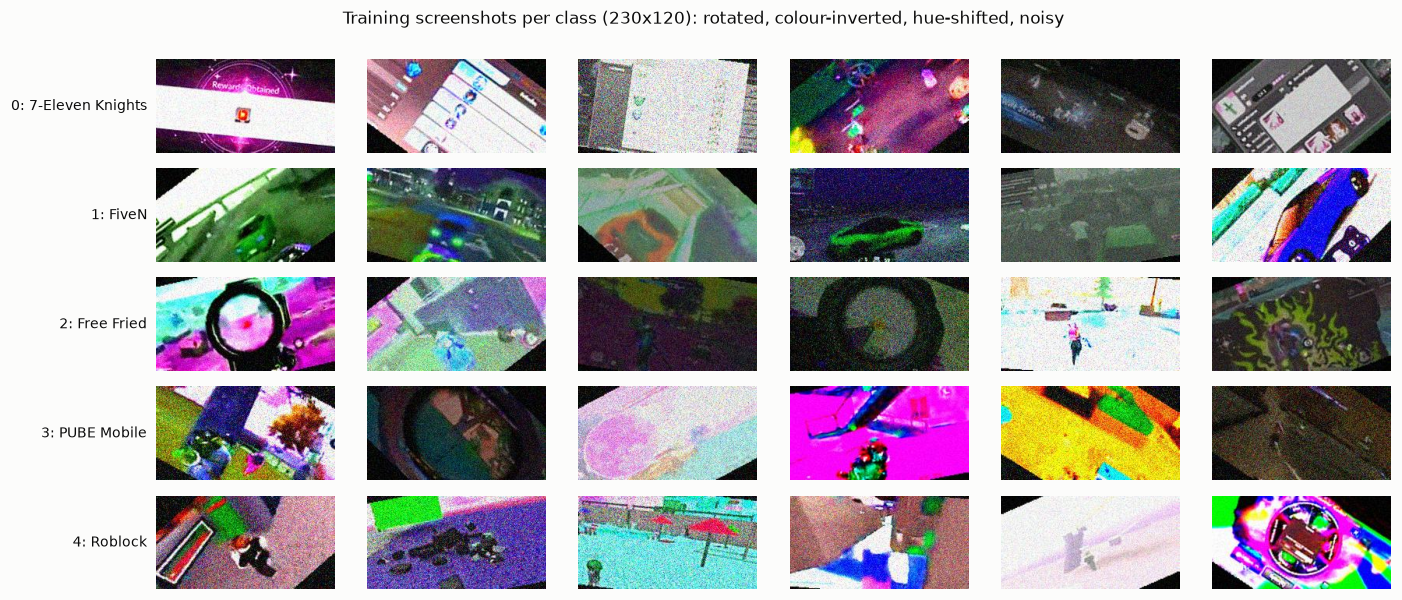

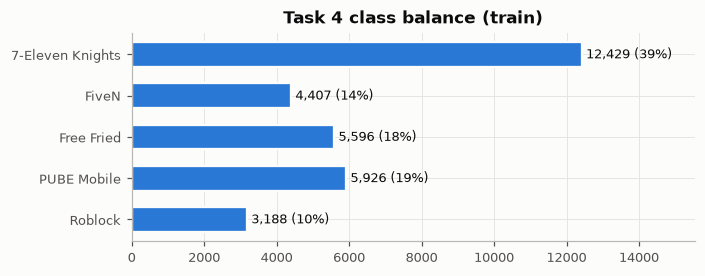

image sizes (W,H) in a 300-image sample: {(230, 120): 300}


In [4]:
from PIL import Image
fig, axes = plt.subplots(5, 6, figsize=(13, 5.4))
for r, cls in enumerate(C.T4_CLASSES):
    ids = t4_train[t4_train["class"] == cls].sample(6, random_state=7)
    for c, p in enumerate(ids.path):
        axes[r, c].imshow(Image.open(p)); axes[r, c].axis("off")
    axes[r, 0].text(-12, 60, f"{r}: {C.T4_CLASS_NAMES[r]}", ha="right", va="center", fontsize=9)
fig.suptitle("Training screenshots per class (230x120): rotated, colour-inverted, hue-shifted, noisy", y=1.0, fontsize=11)
plt.tight_layout(); savefig(fig, "t4_eda_samples"); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 2.6))
vc4 = t4_train["class"].value_counts().reindex(C.T4_CLASSES)
ax.barh(C.T4_CLASS_NAMES[::-1], vc4.values[::-1], color=CAT[0], height=0.6, **viz.bar_gap())
for i, v in enumerate(vc4.values[::-1]):
    ax.text(v, i, f" {v:,} ({v / vc4.sum():.0%})", va="center", fontsize=8.5)
ax.set_xlim(0, vc4.max() * 1.25); ax.set_title("Task 4 class balance (train)")
plt.tight_layout(); savefig(fig, "t4_eda_balance"); plt.show()
sizes = pd.Series([Image.open(p).size for p in t4_train.path.sample(300, random_state=0)]).value_counts()
print("image sizes (W,H) in a 300-image sample:", sizes.to_dict())

**Findings.** Every image is exactly **230×120 (aspect ≈ 1.92:1)**. The screenshots are deliberately corrupted: random rotations and shears with black borders, colour inversion, extreme hue shifts, heavy Gaussian noise and blur. The classes are imbalanced (7-Eleven Knights 39% vs Roblock 10%). Implications: (1) keep the wide aspect ratio rather than squash to a 224×224 square; (2) use training augmentations that *reproduce* these corruptions; (3) after training, tune the macro-F1 decision rule on OOF probabilities.

### Data-quality audit
Adversarial validation (train vs test), missing values vs target, impossible values, duplicates and collinearity, computed by `src/audit.py` on features only (see the master notebook §3.6).

In [5]:
from src import audit
display(pd.DataFrame(audit.image_audit(task4.DATA, {"train": t4_train, "test": t4_test})).T.rename_axis("Task 4 images"))

,images,unreadable,sizes,near-blank (pixel std < 5),mean brightness,within train,within test,test equal to a train image
Task 4 images,,,,,,,,
train,31546,0,"{(230, 120): 31546}",41,114.8000,NaN,NaN,NaN
test,25889,0,"{(230, 120): 25889}",0,105.2000,NaN,NaN,NaN
duplicates,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000


**Audit findings.**
* **Missing values in Tasks 1–3:** no column is informative at p < 0.001. The cells are missing completely at random.
* **Impossible values:** none need cleaning. No percentage leaves [0, 100]. Several bounded scores are clipped at their limits (e.g. 8% of `aiming_smoothness` = 1 in Task 1), which trees handle. `account_age_days = 999` in Tasks 2/3 is not a sentinel: neighbouring values are just as frequent.
* **Duplicates / collinearity:** no duplicate rows within or across splits and no constant columns. The only collinear pairs are known structure: historical vs previous-month spending (Task 3, ratio 0.30–0.40) and the per-period location and skill-rating series (Task 5).
* **Task 4:** all 57,435 images are readable, all 230×120, with no duplicates within or across splits. 41 near-blank training frames (0.13%) are kept. Test images are darker on average (brightness 105 vs 115), part of the known test shift (§7.4).

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

## 4.4 Task 4: aspect-preserving resize and corruption-matched augmentation
Inputs are resized to **160×320** (2:1). That is a 4% horizontal stretch, versus the 48% width compression of a square 224×224 resize. Training augmentation: horizontal flip (never vertical, since HUDs are vertically anchored), aspect-correct affine (±25° rotation, ±8° shear, 0.85–1.15 scale, ±8% shift, black fill like the data), **RandAugment** (2 ops, magnitude 9, re-drawn for every chunk of 8 images), per-sample brightness/contrast/saturation and **full-circle hue rotation** in YIQ space, random inversion, grayscale, Gaussian noise / blur and random erasing. Each batch also gets **Mixup** (α = 0.4) or **CutMix** (α = 1) with probability 0.8, plus **label smoothing** 0.1.

*Engineering note:* the first version applied these per image in CPU DataLoader workers. On this Windows laptop that starved the GPU (utilisation swung between 0% and 100%) and deadlocked once on worker re-spawn. All 31.5k images are now decoded once into a 2.6 GB uint8 array and **augmented batched on the GPU**, roughly 2.3× faster.

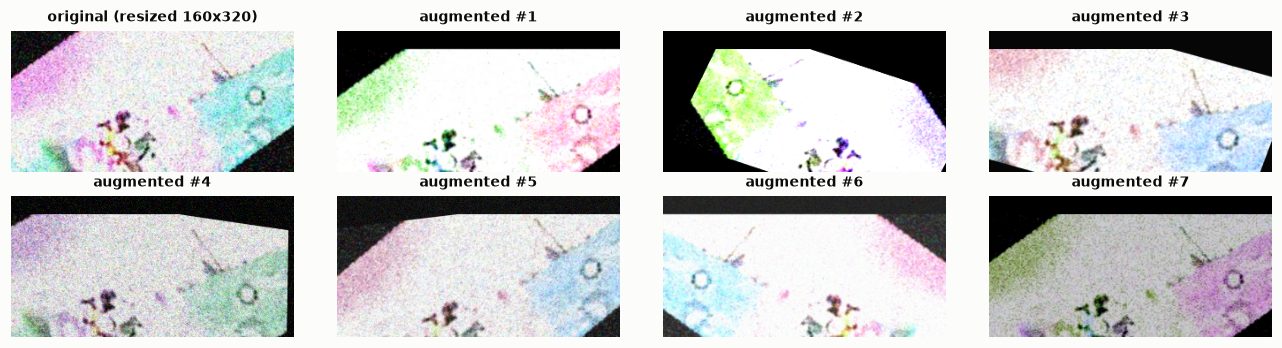

In [6]:
# The whole augmentation pipeline runs batched on the GPU (see src/task4.py: GPUAugment)
aug = task4.GPUAugment()
one = task4.load_uint8([t4_train.path.iloc[3]])
x = task4.to_gpu_batch(np.repeat(one, 8, axis=0), (160, 320), DEVICE)
torch.manual_seed(0)
xa = aug(x)
mean = torch.tensor(task4.MEAN, device=DEVICE).view(1, 3, 1, 1); std = torch.tensor(task4.STD, device=DEVICE).view(1, 3, 1, 1)
vis = (xa * std + mean).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(2, 4, figsize=(12, 3.2))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x[0].permute(1, 2, 0).cpu().numpy() if i == 0 else vis[i])
    ax.set_title("original (resized 160x320)" if i == 0 else f"augmented #{i}", fontsize=9); ax.axis("off")
plt.tight_layout(); savefig(fig, "t4_fe_aug"); plt.show()

<a id="5"></a>
# 5. Model Training & Evaluation

**Validation protocol.** 5 folds (seed 42), `StratifiedKFold` on the game label (`scripts/train_task4.py`). Every model produces out-of-fold (OOF) predictions for every training row: they give honest scores, feed threshold/weight tuning and serve as stacking inputs. Test predictions average the 5 fold models. Results are cached in `outputs/preds/*.npz`; delete a file to retrain that model.

In [7]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer


def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

### 5.1 Per-fold learning curves of the fine-tuned backbones

Task 4 backbones with complete 5-fold caches: {'cnxt': ('convnext_tiny.in12k_ft_in1k', (160, 320)), 'deit3': ('deit3_small_patch16_384.fb_in22k_ft_in1k', (192, 384))}


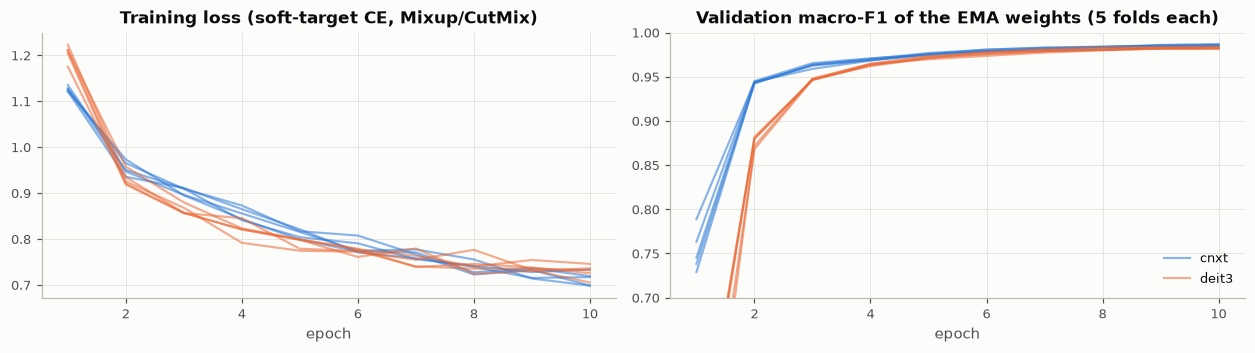

In [8]:
T4_BACKBONES = {   # tag -> (timm model, input HxW) as trained by scripts/train_task4.py
    "cnxt": ("convnext_tiny.in12k_ft_in1k", (160, 320)),
    "deit3": ("deit3_small_patch16_384.fb_in22k_ft_in1k", (192, 384)),
}
fold_done = lambda tag: all((C.PRED_DIR / f"t4_{tag}_fold{f}.npz").exists() for f in range(N_FOLDS))
if not fold_done("cnxt") and RUN_T4_TRAINING:
    subprocess.run([sys.executable, "-u", "scripts/train_task4.py", "--model", T4_BACKBONES["cnxt"][0],
                    "--tag", "cnxt", "--epochs", "10"], check=True)
T4_TAGS = [tag for tag in T4_BACKBONES if fold_done(tag)]
assert "cnxt" in T4_TAGS, "Task 4 fold caches missing (run scripts/train_task4.py or set RUN_T4_TRAINING=True)"
print("Task 4 backbones with complete 5-fold caches:", {t: T4_BACKBONES[t] for t in T4_TAGS})

log_dir = C.OUT / "logs"
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))
for j, tag in enumerate(T4_TAGS):
    for f in range(N_FOLDS):
        h = pd.DataFrame(json.loads((log_dir / f"t4_{tag}_fold{f}_history.json").read_text()))
        lab = tag if f == 0 else None
        axes[0].plot(h.epoch + 1, h.loss, color=CAT[j], alpha=0.55, lw=1.4, label=lab)
        axes[1].plot(h.epoch + 1, h.val_f1, color=CAT[j], alpha=0.55, lw=1.4, label=lab)
axes[0].set_title("Training loss (soft-target CE, Mixup/CutMix)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Validation macro-F1 of the EMA weights (5 folds each)"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0.7, 1.0)
axes[1].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "t4_curves"); plt.show()

<a id="6"></a>
# 6. Hyperparameter Tuning

No Optuna search for Task 4: one fine-tuning run costs 2-3 GPU hours on this laptop. The recipe uses standard fine-tuning settings (AdamW, weight decay 0.05, 1-epoch warm-up + cosine schedule, 10 epochs, batch 64, label smoothing 0.1, Mixup/CutMix p = 0.8, EMA 0.999). The learning rate is set per backbone family: 2e-4 for the CNN and 1e-4 for the ViT, the usual ratio for fine-tuning the two families. The only post-hoc parameters, the class-wise decision multipliers, are tuned on OOF probabilities in §7.

<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

Fold models of architecturally different backbones are averaged in probability space, and class-wise decision multipliers $\hat y=\arg\max_c w_c P_{ic}$ are tuned on the OOF blend for macro-$F_1$.

## 7.4 Task 4: Game title detection (macro-F1)
For each backbone, every fold model (final EMA weights) predicts its held-out fold with h-flip TTA, which gives OOF probabilities. Test probabilities are the mean over the 5 folds × 2 views. The two backbones come from different architecture families, and their probabilities are averaged:
* **ConvNeXt-Tiny** (CNN, IN-12k) at 160×320;
* **DeiT-III Small/16** (Vision Transformer, IN-22k) at 192×384, with position embeddings resampled to the 12×24 token grid.

Class-wise multipliers are then tuned on the OOF blend for macro-F1, and kept only if they help. Two more backbones were tried and dropped on OOF evidence:
* EfficientNetV2-S diverged at lr 3e-4 (epoch-0 loss above uniform).
* DINOv2 ViT-S/14 (self-supervised, at 154×308, lr 5e-5, wider zoom augmentation 0.7–1.3) reached only 0.9705 macro-F1 on fold 0, versus 0.986 / 0.985 for the two kept backbones. Adding it lowered the fold-0 ensemble at every weight tried (0.9878 → 0.9863 at 1/3 weight, 0.9874 at 0.2), and it was *less* confident on test images, not more. Its run was stopped after fold 0 (`outputs/preds/t4_dino_fold0.npz`).

**Why a second architecture? A test-set shift.** The next cell compares the models' confidence on test images against held-out training images. Test images are visibly harder: far more low-confidence predictions and lower agreement between fold models. They also show a different class mix, with fewer 7-Eleven Knights screenshots. So the OOF macro-F1 is an *optimistic* estimate of leaderboard performance. The shift is not a low-level one: binned by brightness, saturation, contrast or the black rotation border, test confidence is lower in *every* bin. The test images mostly show content (scenes, maps, menus) that the training set does not cover. Ensembling architecturally different models is the standard remedy that stays within the rules, and ViTs are known to be more robust to distribution shift than CNNs. We deliberately do **not** apply transductive label-shift correction (EM prior re-estimation on test predictions, Saerens et al. 2002), because it would adapt the model using test data.

fold,0,1,2,3,4,OOF (all folds)
backbone,,,,,,
cnxt,0.9859,0.9879,0.9851,0.9875,0.9860,0.9865
deit3,0.9849,0.9842,0.9844,0.9830,0.9829,0.9839
probability average,NaN,NaN,NaN,NaN,NaN,0.9881


OOF macro-F1 argmax 0.9881 -> with class multipliers 0.9887 | accuracy 0.9899


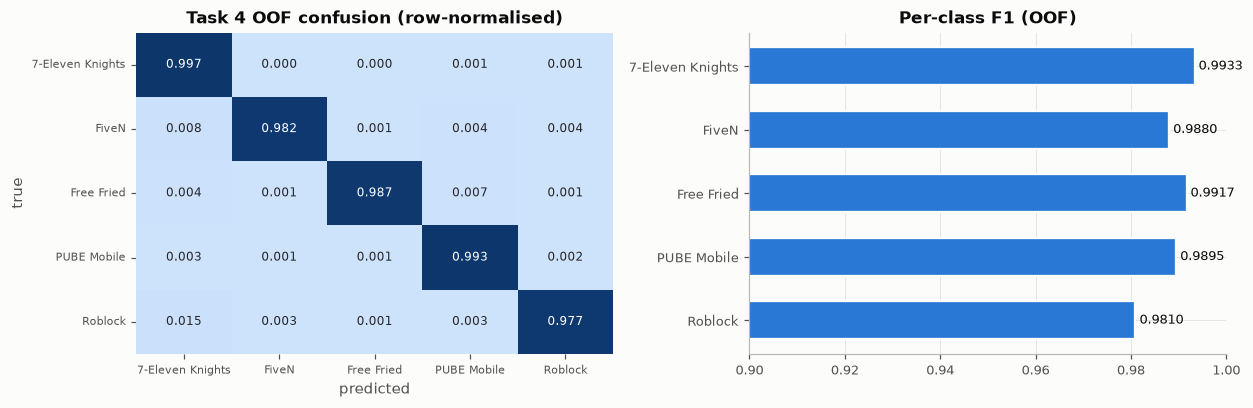

In [9]:
y4 = t4_train.label.values
oof_tag, test_tag, per_fold = {}, {}, []
for tag in T4_TAGS:
    oof_tag[tag], test_tag[tag] = np.zeros((len(y4), 5)), np.zeros((len(t4_test), 5))
    for f in range(N_FOLDS):
        z = np.load(C.PRED_DIR / f"t4_{tag}_fold{f}.npz")
        oof_tag[tag][z["val_idx"]] = z["val_probs"]
        test_tag[tag] += z["test_probs"] / N_FOLDS
        per_fold.append([tag, f, f1_score(y4[z["val_idx"]], z["val_probs"].argmax(1), average="macro")])
pf = pd.DataFrame(per_fold, columns=["backbone", "fold", "macro-F1"]).pivot(index="backbone", columns="fold", values="macro-F1")
pf["OOF (all folds)"] = [macro_f1(y4, oof_tag[t].argmax(1)) for t in pf.index]
oof4 = np.mean([oof_tag[t] for t in T4_TAGS], axis=0)
test4 = np.mean([test_tag[t] for t in T4_TAGS], axis=0)
if len(T4_TAGS) > 1:
    pf.loc["probability average"] = [np.nan] * N_FOLDS + [macro_f1(y4, oof4.argmax(1))]
display(pf.round(4))
W4, SCORE4 = optimize_class_weights(y4, oof4)
base4 = macro_f1(y4, oof4.argmax(1))
print(f"OOF macro-F1 argmax {base4:.4f} -> with class multipliers {SCORE4:.4f} | accuracy {(oof4.argmax(1) == y4).mean():.4f}")
if SCORE4 - base4 < 0.0005:           # not worth the extra degrees of freedom
    W4, SCORE4 = np.ones(5), base4
pred4 = apply_class_weights(test4, W4)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
cm4 = confusion_matrix(y4, apply_class_weights(oof4, W4), normalize="true")
sns.heatmap(cm4, annot=True, fmt=".3f", cmap=SEQ_CMAP, vmin=0, vmax=1, xticklabels=C.T4_CLASS_NAMES, yticklabels=C.T4_CLASS_NAMES,
            cbar=False, ax=axes[0], annot_kws={"size": 8})
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Task 4 OOF confusion (row-normalised)")
axes[0].tick_params(labelsize=7.5)
pc4 = f1_score(y4, apply_class_weights(oof4, W4), average=None)
axes[1].barh(C.T4_CLASS_NAMES[::-1], pc4[::-1], color=CAT[0], height=0.6, **viz.bar_gap())
for i, v in enumerate(pc4[::-1]):
    axes[1].text(v, i, f" {v:.4f}", va="center", fontsize=8.5)
axes[1].set_xlim(0.9, 1.0); axes[1].set_title("Per-class F1 (OOF)")
plt.tight_layout(); savefig(fig, "t4_confusion"); plt.show()
summary.append(["Task 4", "macro-F1", SCORE4, f"{' + '.join(T4_TAGS)} 5-fold, GPU aug + Mixup/CutMix, EMA, h-flip TTA"])

,OOF share max-p<0.7,TEST share max-p<0.7,pairwise fold agreement on TEST
model,,,
cnxt,0.0182,0.2086,0.9036
deit3,0.0244,0.1833,0.9236
cnxt vs deit3 (test),NaN,NaN,0.9011


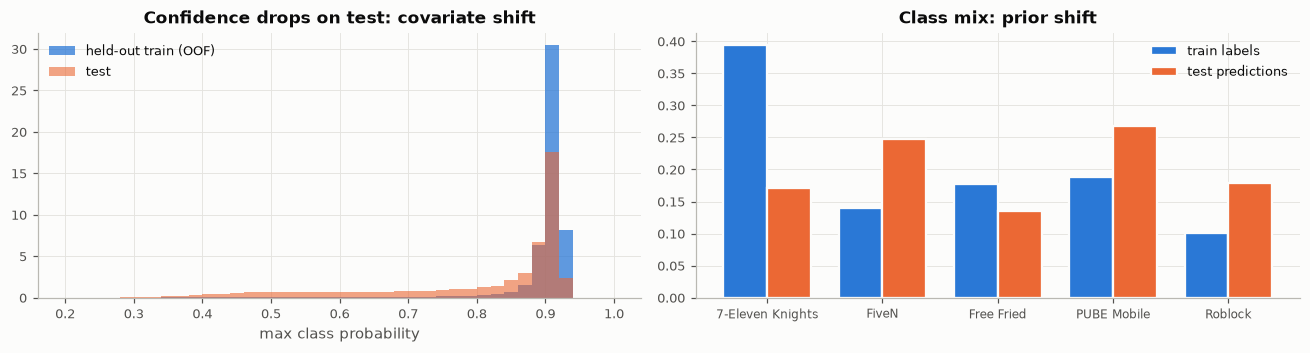

In [10]:
# Distribution-shift diagnostics: held-out train images (OOF) vs test images
fold_preds = {tag: [np.load(C.PRED_DIR / f"t4_{tag}_fold{f}.npz")["test_probs"].argmax(1) for f in range(N_FOLDS)] for tag in T4_TAGS}
rows = []
for tag in T4_TAGS:
    fp = fold_preds[tag]
    agree = np.mean([np.mean(fp[i] == fp[j]) for i in range(N_FOLDS) for j in range(i + 1, N_FOLDS)])
    rows.append([tag, (oof_tag[tag].max(1) < 0.7).mean(), (test_tag[tag].max(1) < 0.7).mean(), agree])
for i, a in enumerate(T4_TAGS):
    for b in T4_TAGS[i + 1:]:
        rows.append([f"{a} vs {b} (test)", np.nan, np.nan, np.mean(test_tag[a].argmax(1) == test_tag[b].argmax(1))])
display(pd.DataFrame(rows, columns=["model", "OOF share max-p<0.7", "TEST share max-p<0.7", "pairwise fold agreement on TEST"]).set_index("model").round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
bins = np.linspace(0.2, 1.0, 41)
axes[0].hist(oof4.max(1), bins=bins, color=CAT[0], alpha=0.75, density=True, label="held-out train (OOF)")
axes[0].hist(test4.max(1), bins=bins, color=CAT[1], alpha=0.6, density=True, label="test")
axes[0].set_xlabel("max class probability"); axes[0].set_title("Confidence drops on test: covariate shift"); axes[0].legend(loc="upper left")
xs = np.arange(5); wdt = 0.38
axes[1].bar(xs - wdt / 2, np.bincount(y4, minlength=5) / len(y4), wdt, color=CAT[0], label="train labels", **viz.bar_gap())
axes[1].bar(xs + wdt / 2, np.bincount(pred4, minlength=5) / len(pred4), wdt, color=CAT[1], label="test predictions", **viz.bar_gap())
axes[1].set_xticks(xs); axes[1].set_xticklabels(C.T4_CLASS_NAMES, fontsize=8); axes[1].set_title("Class mix: prior shift"); axes[1].legend()
plt.tight_layout(); savefig(fig, "t4_shift"); plt.show()

## 7.6 Final model: combine Train+Val (competition rule)
The rules say: *"Combine Train+Val for training"* and *"✅ Allowed: combining Train and Validation sets for final model training after all validation is complete."* Everything above was validation: the 5-fold OOF predictions are what we scored, tuned and stacked on. Each fold model saw only 80% of the labelled data. Now, with every decision fixed, each level-1 model is **retrained once on 100% of the labelled rows**:

* **Task 4:** one extra model per backbone is trained on all 31,546 images with the identical recipe (`scripts/train_task4.py --full`).

The final level-1 test input is the **average of the 5-fold models and the full-data model**. Both are legitimate final models, and averaging them lowers variance. **Nothing is re-tuned:** the stacker, the threshold τ, the class multipliers, the L1 blend weights, the zero gate and the scale all keep their out-of-fold values. Task 5 has no labelled data, so its detectors are already fitted on all available data.

In [11]:
from src.modeling import refit_full, refit_full_sklearn
FULL_W = 0.5                                     # weight of the full-data model in the final test input
blend_full = lambda fold_test, full_test: (1 - FULL_W) * np.asarray(fold_test) + FULL_W * np.asarray(full_test)
changes = []

# ---- Task 4
test4_final = []
for tag in T4_TAGS:
    pth = C.PRED_DIR / f"t4_{tag}_full.npz"
    test4_final.append(blend_full(test_tag[tag], np.load(pth)["test_probs"]) if pth.exists() else test_tag[tag])
    print(f"Task 4 {tag}: full-data model {'included' if pth.exists() else 'NOT found -> 5-fold ensemble only'}")
pred4_final = apply_class_weights(np.mean(test4_final, axis=0), W4)
changes.append(["Task 4", "labels changed", np.mean(pred4_final != pred4), ""])

display(pd.DataFrame(changes, columns=["task", "check", "value", "note"]).set_index("task").round(4))
pred4 = pred4_final   # used by section 9

Task 4 cnxt: full-data model included
Task 4 deit3: full-data model included


,check,value,note
task,,,
Task 4,labels changed,0.0266,


<a id="8"></a>
# 8. Feature Importance Analysis

**Grad-CAM** (Selvaraju et al., 2017) on the last ConvNeXt stage shows which pixels drive each decision.

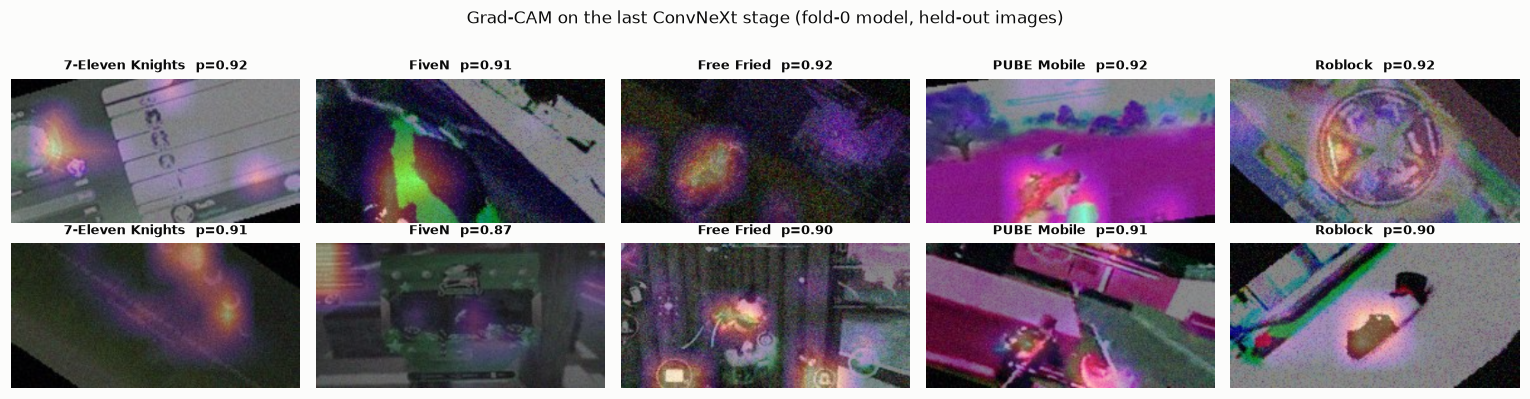

In [12]:
cam_model = task4.create_model("convnext_tiny.in12k_ft_in1k", pretrained=False).to(DEVICE)
cam_model.load_state_dict(torch.load(C.MODEL_DIR / "t4_cnxt_fold0.pt", map_location=DEVICE))
gc = task4.GradCAM(cam_model, cam_model.stages[-1])
z0 = np.load(C.PRED_DIR / "t4_cnxt_fold0.npz")
va_idx0, vp0 = z0["val_idx"], z0["val_probs"]
pick = []
for k in range(5):
    ok = va_idx0[(y4[va_idx0] == k) & (vp0.argmax(1) == k)]
    pick += list(np.random.default_rng(k).choice(ok, 2, replace=False))
arr = task4.load_uint8([t4_train.path.iloc[i] for i in pick])
x = task4.normalize(task4.to_gpu_batch(arr, (160, 320), DEVICE))
cams, probs = gc(x)
fig, axes = plt.subplots(2, 5, figsize=(14, 3.6))
for i, ax in enumerate(axes.T.ravel()):
    img = task4.to_gpu_batch(arr[i:i + 1], (160, 320), DEVICE)[0].permute(1, 2, 0).cpu().numpy()
    ax.imshow(img); ax.imshow(cams[i], cmap="magma", alpha=0.45); ax.axis("off")
    k = y4[pick[i]]
    ax.set_title(f"{C.T4_CLASS_NAMES[k]}  p={probs[i, k]:.2f}", fontsize=8.5)
fig.suptitle("Grad-CAM on the last ConvNeXt stage (fold-0 model, held-out images)", y=1.02, fontsize=11)
plt.tight_layout(); savefig(fig, "t4_gradcam"); plt.show()
del cam_model; torch.cuda.empty_cache()

**Business reading (game detection).** The attention maps land on **game-specific HUD and art assets**: menus, minimaps, character art and vehicle or world textures, rather than on the noise or the black rotation borders. This shows the corruption-matched augmentation taught the network to ignore artefacts. On in-distribution screenshots (OOF macro-F1 ≈ 0.99) the classifier can auto-route the 2,000 daily support tickets to the right game team. It can also verify "Play Multiple Games" campaign screenshots at scale. The §7.4 shift analysis argues for a **confidence gate** in production: predictions with max probability < 0.7 go to a human. That is under 2% of in-distribution traffic, but about a fifth of the shifted test-style traffic, and those hard cases are the ones that should be collected and labelled to retrain the model.

<a id="9"></a>
# 9. Submission

The Task 4 column of the submission: `task4` is a plain integer code, as defined in the datacard. The part is written to `outputs/submission_parts/task4.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [13]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task4": pred4.astype(int)})
assert len(part) == C.N_TEST == len(t4_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task4"].notna().all() and set(part.task4.unique()) <= {0, 1, 2, 3, 4}
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task4.csv", index=False)
print(f"saved {part_dir / 'task4.csv'} | {part.shape}")
display(part.head())
print("predicted class shares:", dict(zip(C.T4_CLASSES, np.round(np.bincount(pred4, minlength=5) / len(pred4), 3))))

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task4.csv | (25889, 2)


,id,task4
0,ANS00001,1
1,ANS00002,0
2,ANS00003,3
3,ANS00004,3
4,ANS00005,3


predicted class shares: {'7-11k': np.float64(0.17), 'fiveN': np.float64(0.248), 'freefried': np.float64(0.136), 'pube': np.float64(0.269), 'roblock': np.float64(0.178)}


<a id="10"></a>
# 10. Conclusion

In [14]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 4,macro-F1,0.9887,"cnxt + deit3 5-fold, GPU aug + Mixup/CutMix, EMA, h-flip TTA"


| Task | Key insight | What moved the score |
|---|---|---|
| 4 Game title | Corrupted screenshots, 2:1 aspect; shifted test set | Aspect-preserving inputs, **GPU corruption-matched augmentation**, Mixup/CutMix, EMA, TTA; **CNN + ViT ensemble** for shift robustness |